In [2]:
import pandas as pd
import json
import collections
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import requests
from tqdm import tqdm

In [3]:
METADATA_DIR = "../../../data/immunotherapy_cohorts/IMMotion150/EGAD00001004183-metadata"

# run_sample.csv has semicolon-separated key=value attributes — easier to parse than samples.csv JSON
run_sample = pd.read_csv(f"{METADATA_DIR}/run_sample.csv")

def parse_sample_attributes(attr_str):
    attrs = {}
    if pd.isna(attr_str):
        return attrs
    for item in str(attr_str).split(";"):
        if "=" in item:
            k, v = item.split("=", 1)
            attrs[k.strip()] = v.strip()
    return attrs

attrs_df = run_sample["sample_attributes"].apply(parse_sample_attributes)
attrs_df = pd.DataFrame(list(attrs_df))

# Combine with run/sample accession IDs
meta = pd.concat([run_sample[["sample_alias", "sample_accession_id", "run_accession_id"]], attrs_df], axis=1)

# RNA-seq samples are those with AnnoRNASampleID present
rna_meta = meta[meta["AnnoRNASampleID"].notna()].copy()

# Cast numeric fields
for col in ["PFS", "CNSR_PFS", "TMB", "TNB", "CD8A_IHC", "CD31_IHC", "ICSCORE"]:
    rna_meta[col] = pd.to_numeric(rna_meta[col], errors="coerce")

# Canonical response label: responder = CR or PR
rna_meta["response_binary"] = rna_meta["BestResponse"].map(
    {"CR": 1, "PR": 1, "SD": 0, "PD": 0}  # NE → NaN automatically
)

print(f"Total samples in metadata: {len(meta)}")
print(f"RNA-seq samples:           {len(rna_meta)}")
print(f"  with PFS + CNSR_PFS:     {rna_meta['PFS'].notna().sum()}")
print(f"  with BestResponse:       {rna_meta['BestResponse'].notna().sum()}")
print(f"  with binary label (excl. NE): {rna_meta['response_binary'].notna().sum()}")

rna_meta.head(3)

Total samples in metadata: 589
RNA-seq samples:           263
  with PFS + CNSR_PFS:     263
  with BestResponse:       256
  with binary label (excl. NE): 247


,sample_alias,sample_accession_id,run_accession_id,AnnoRNASampleID,AnonPatID,ARM,BestResponse,CD31_IHC,CD8A_IHC,CNSR_PFS,...,MTOR,PBRM1,SETD2,TMB,TNB,TP53,VHL,AnnoNormalWESID,AnnoTumorWESID,response_binary
0,007603faf7a3,EGAN00001749440,EGAR00001766573,007603faf7a3,19690601982438,Atezo+Bev,PD,6.6667,0.32,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,0098b8010fb0,EGAN00001749441,EGAR00001766574,0098b8010fb0,262873171124023,Sunitinib,PD,14.5679,1.77,1,...,nonMUT,nonMUT,nonMUT,20.0,3.0,nonMUT,nonMUT,NaN,NaN,0.0
3,014307e64a29,EGAN00001749442,EGAR00001766809,014307e64a29,159979697066613,Sunitinib,PR,NaN,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


/tmp/ipykernel_2468358/1148265123.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  orr = rna_meta.groupby("ARM").apply(


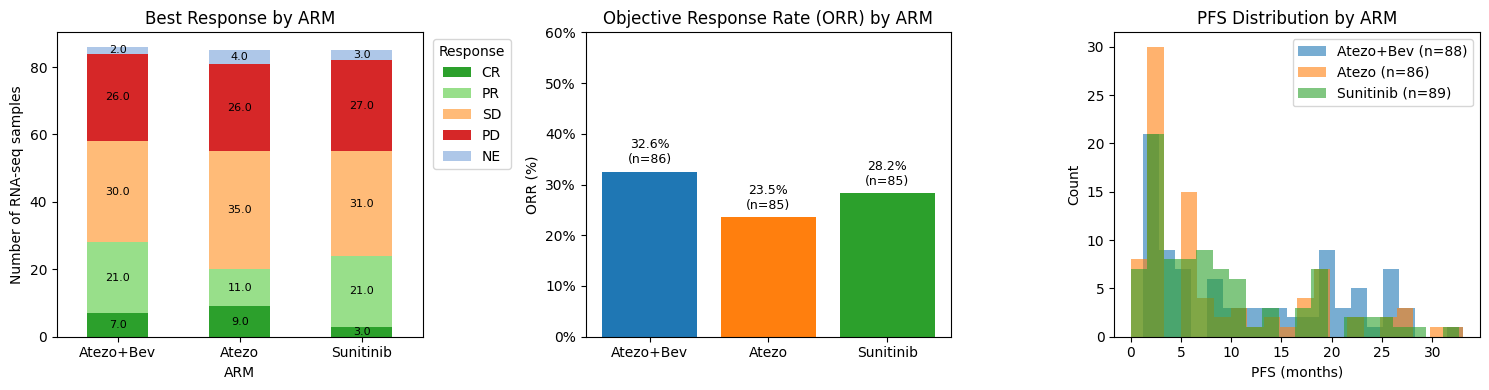

            n  CR  PR  SD  PD  NE  missing_response  has_PFS  median_PFS  pfs_event_rate    ORR (%)
ARM                                                                                                
Atezo+Bev  88   7  21  30  26   2                 2       88   10.086242        0.340909  33.333333
Atezo      86   9  11  35  26   4                 1       86    5.437372        0.406977  24.691358
Sunitinib  89   3  21  31  27   3                 4       89    6.669405        0.382022  29.268293


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- BestResponse by ARM ---
ax = axes[0]
response_order = ["CR", "PR", "SD", "PD", "NE"]
arm_order = ["Atezo+Bev", "Atezo", "Sunitinib"]
resp_counts = (
    rna_meta[rna_meta["BestResponse"].notna()]
    .groupby(["ARM", "BestResponse"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=arm_order, columns=response_order, fill_value=0)
)
colors = {"CR": "#2ca02c", "PR": "#98df8a", "SD": "#ffbb78", "PD": "#d62728", "NE": "#aec7e8"}
resp_counts.plot(kind="bar", stacked=True, ax=ax,
                 color=[colors[c] for c in resp_counts.columns], legend=True, rot=0)
ax.set_title("Best Response by ARM")
ax.set_xlabel("ARM")
ax.set_ylabel("Number of RNA-seq samples")
ax.legend(title="Response", bbox_to_anchor=(1.01, 1), loc="upper left")
for c in ax.containers:
    ax.bar_label(c, label_type="center", fmt="%d", fontsize=8,
                 labels=[v if v > 0 else "" for v in c.datavalues])

# --- ORR (CR+PR) by ARM ---
ax = axes[1]
orr = rna_meta.groupby("ARM").apply(
    lambda x: pd.Series({
        "ORR (CR+PR)": (x["BestResponse"].isin(["CR", "PR"])).sum() / x["BestResponse"].notna().sum() * 100,
        "n": x["BestResponse"].notna().sum()
    })
).reindex(arm_order)
bars = ax.bar(orr.index, orr["ORR (CR+PR)"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax.set_title("Objective Response Rate (ORR) by ARM")
ax.set_ylabel("ORR (%)")
ax.set_ylim(0, 60)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
for bar, (arm, row) in zip(bars, orr.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"{row['ORR (CR+PR)']:.1f}%\n(n={int(row['n'])})", ha="center", va="bottom", fontsize=9)

# --- PFS distribution by ARM ---
ax = axes[2]
for arm, color in zip(arm_order, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    subset = rna_meta[(rna_meta["ARM"] == arm) & rna_meta["PFS"].notna()]["PFS"]
    ax.hist(subset, bins=20, alpha=0.6, label=f"{arm} (n={len(subset)})", color=color)
ax.set_title("PFS Distribution by ARM")
ax.set_xlabel("PFS (months)")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.savefig("IMMotion150_cohort_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Tabular summary
summary = rna_meta.groupby("ARM").agg(
    n=("AnnoRNASampleID", "count"),
    CR=("BestResponse", lambda x: (x == "CR").sum()),
    PR=("BestResponse", lambda x: (x == "PR").sum()),
    SD=("BestResponse", lambda x: (x == "SD").sum()),
    PD=("BestResponse", lambda x: (x == "PD").sum()),
    NE=("BestResponse", lambda x: (x == "NE").sum()),
    missing_response=("BestResponse", lambda x: x.isna().sum()),
    has_PFS=("PFS", lambda x: x.notna().sum()),
    median_PFS=("PFS", "median"),
    pfs_event_rate=("CNSR_PFS", lambda x: (x == 0).sum() / x.notna().sum()),
).reindex(arm_order)
summary["ORR (%)"] = (summary["CR"] + summary["PR"]) / (summary["n"] - summary["NE"] - summary["missing_response"]) * 100
print(summary.to_string())

In [5]:
# Join RNA-seq sample accession IDs with file accession IDs (EGAFs)
sample_file = pd.read_csv(f"{METADATA_DIR}/sample_file.csv")

rna_accessions = set(rna_meta["sample_accession_id"])
rna_files = sample_file[sample_file["sample_accession_id"].isin(rna_accessions)].copy()

print(f"RNA-seq samples:  {len(rna_accessions)}")
print(f"Fastq files (2 per sample, paired-end): {len(rna_files)}")
print(f"Unique EGAF IDs:  {rna_files['file_accession_id'].nunique()}")
print()

# Save EGAF IDs for download
# Command
# cat /data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMMotion150/RNA/rna_seq_egaf_ids.txt | \
#xargs -P 8 -I {} pyega3 -cf /data/rbg/users/ashyamal/credentials.json -c 2 fetch \
#    --output-dir /data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMMotion150/RNA \
#    {}
OUT_DIR = "../../../data/immunotherapy_cohorts/IMMotion150/RNA"
egaf_path = f"{OUT_DIR}/rna_seq_egaf_ids.txt"
rna_files["file_accession_id"].to_csv(egaf_path, index=False, header=False)
print(f"Saved {len(rna_files)} EGAF IDs to {egaf_path}")

# Also save a full manifest with sample alias, ARM, BestResponse for easy cross-referencing
manifest = rna_files.merge(
    rna_meta[["sample_accession_id", "AnnoRNASampleID", "AnonPatID", "ARM",
               "BestResponse", "response_binary", "PFS", "CNSR_PFS", "MSKCC", "Stage"]],
    on="sample_accession_id", how="left"
).sort_values(["AnnoRNASampleID", "file_name"])

manifest_path = f"{OUT_DIR}/rna_seq_download_manifest.csv"
manifest.to_csv(manifest_path, index=False)
print(f"Saved download manifest to {manifest_path}")
manifest.head(6)

RNA-seq samples:  263
Fastq files (2 per sample, paired-end): 526
Unique EGAF IDs:  526

Saved 526 EGAF IDs to ../../../data/immunotherapy_cohorts/IMMotion150/RNA/rna_seq_egaf_ids.txt
Saved download manifest to ../../../data/immunotherapy_cohorts/IMMotion150/RNA/rna_seq_download_manifest.csv


,sample_accession_id,sample_alias,file_name,file_accession_id,AnnoRNASampleID,AnonPatID,ARM,BestResponse,response_binary,PFS,CNSR_PFS,MSKCC,Stage
124,EGAN00001749440,007603faf7a3,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035814,007603faf7a3,19690601982438,Atezo+Bev,PD,0.0,2.661191,1,Poor,STAGE IV
125,EGAN00001749440,007603faf7a3,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035815,007603faf7a3,19690601982438,Atezo+Bev,PD,0.0,2.661191,1,Poor,STAGE IV
126,EGAN00001749441,0098b8010fb0,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035816,0098b8010fb0,262873171124023,Sunitinib,PD,0.0,2.792608,1,Favorable,STAGE II
127,EGAN00001749441,0098b8010fb0,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035817,0098b8010fb0,262873171124023,Sunitinib,PD,0.0,2.792608,1,Favorable,STAGE II
128,EGAN00001749442,014307e64a29,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035974,014307e64a29,159979697066613,Sunitinib,PR,1.0,27.433265,0,Intermediate,STAGE III
129,EGAN00001749442,014307e64a29,EGAS00001002928_WO29074_NGS_Raw_data_RNASeq_20...,EGAF00002035975,014307e64a29,159979697066613,Sunitinib,PR,1.0,27.433265,0,Intermediate,STAGE III


In [6]:
import subprocess

egaf_path = f"{OUT_DIR}/rna_seq_egaf_ids.txt"
dataset_files_path = f"{METADATA_DIR}/dataset_files.txt"

result = subprocess.run(
    f"grep -Ff {egaf_path} {dataset_files_path} | awk '{{sum += $6}} END {{printf \"%.2f\", sum / 1e9}}'",
    shell=True, capture_output=True, text=True
)
print(f"Total RNA-seq download size: {result.stdout} GB")


Total RNA-seq download size: 1258.08 GB


In [7]:
# Number of samples with both RNA-seq and responder information that's note NE
labeled = rna_meta[rna_meta["response_binary"].notna()]
print(f"Samples with RNA-seq + responder/non-responder label (excl. NE): {len(labeled)}")
print(f"  Responders   (CR/PR): {(labeled['response_binary'] == 1).sum()}")
print(f"  Non-responders (SD/PD): {(labeled['response_binary'] == 0).sum()}")

Samples with RNA-seq + responder/non-responder label (excl. NE): 247
  Responders   (CR/PR): 72
  Non-responders (SD/PD): 175
